# Supplementary Figure S10 — mass balance

Standalone, function-free workflow for the two matrix-glass mass-balance calculations and the six selected individual melt inclusions. The seven modeled phases and all scientific selections are unchanged.

**External-data note:** the Fe–Ti oxide compositions come from the Sisson et al. (2019) Glacier Peak dataset. That dataset is not part of the published supplemental workbooks and is not redistributed with this notebook. The apatite and zircon measurements are also read from a separate project SEM workbook. Exact reproduction therefore requires local access to both documented external files.

## Shared setup for Figure S10

In [1]:
from pathlib import Path
from itertools import combinations
import shutil
import subprocess
import tempfile

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S10_Mass_Balance'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S10_Mass_Balance_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
WORKBOOK_PATHS = {
    'S1': Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx'),
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

DECHERT_PRIVATE_ROOT = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc')
USER_PRIVATE_ROOT = Path('/replace/with/the/folder/containing/the/external/project/files')
PRIVATE_ROOT = DECHERT_PRIVATE_ROOT
# PRIVATE_ROOT = USER_PRIVATE_ROOT
SISSON_FETI_WORKBOOK = PRIVATE_ROOT / 'Sources/GP/Sisson 2019/Sisson 2019 Glacier Peak B&G oxides averaged.xls'
ACCESSORY_WORKBOOK = PRIVATE_ROOT / 'Glacier Peak Efforts/GP SEM Data/08042025/Annika_EDS_Current_MML_20260721_combined.xlsx'
for path in [SISSON_FETI_WORKBOOK, ACCESSORY_WORKBOOK]:
    if not path.is_file():
        raise FileNotFoundError(f'Exact reproduction requires the external project file: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 6.80
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
SMALL_BAR_LABEL_SIZE_PT = 6.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT], 'font.size': 8.0,
    'axes.labelsize': 8.0, 'axes.titlesize': 8.0, 'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0, 'legend.fontsize': 8.0, 'legend.title_fontsize': 8.0,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.spines.top': True,
    'axes.spines.right': True, 'axes.linewidth': 0.5, 'lines.linewidth': 0.75,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.major.width': 0.5,
    'ytick.major.width': 0.5, 'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})
print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')
print('External Fe-Ti source:', SISSON_FETI_WORKBOOK)

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S10_Mass_Balance
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 6.8 in
External Fe-Ti source: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Sources/GP/Sisson 2019/Sisson 2019 Glacier Peak B&G oxides averaged.xls


## Figure S10-specific source preparation

The shared setup ends above. This section reads only the source tables needed for S10, derives one composition per qualifying line-scanned crystal, and builds the seven phase endmembers explicitly.

In [2]:
mi_hosts = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')
transects = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Transects').rename(columns={'Sample': 'Sample_Group'})
whole_rock_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Whole_Rock')
kuehn_source = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Kuehn2009')

COMPONENTS = ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MgO', 'CaO', 'Na2O', 'P2O5', 'Zr']
PHASES = ['glass', 'plagioclase', 'orthopyroxene', 'amphibole', 'FeTi_oxide', 'apatite', 'zircon']
GROUP_MEMBERS = {'G': ['76A', '75'], 'B': ['74A', '74D']}

# Determine each line scan's dominant mineral using every supplied point.
scan_counts = transects.groupby(['Linescan_ID', 'Predict_Mineral'], dropna=False).size().rename('count').reset_index()
scan_counts = scan_counts.sort_values(['Linescan_ID', 'count', 'Predict_Mineral'], ascending=[True, False, True])
dominant_rows = scan_counts.drop_duplicates('Linescan_ID').set_index('Linescan_ID')
scan_totals = transects.groupby('Linescan_ID').size()
transects['Dominant_Mineral'] = transects['Linescan_ID'].map(dominant_rows['Predict_Mineral'])
transects['Dominant_Mineral_Fraction'] = transects['Linescan_ID'].map(dominant_rows['count'].div(scan_totals))
transects['group'] = transects['Sample_Group'].map({'76A': 'G', '75': 'G', '74A': 'B', '74D': 'B'})

LINE_SCAN_OXIDES = ['SiO2_SEMMineral_Norm', 'TiO2_SEMMineral_Norm', 'Al2O3_SEMMineral_Norm', 'FeOt_SEMMineral_Norm', 'MnO_SEMMineral_Norm', 'MgO_SEMMineral_Norm', 'CaO_SEMMineral_Norm', 'Na2O_SEMMineral_Norm', 'K2O_SEMMineral_Norm', 'Cr2O3_SEMMineral_Norm', 'P2O5_SEMMineral_Norm']
LINE_SCAN_COMPONENT_COLUMNS = {'SiO2': 'SiO2_SEMMineral_Norm', 'TiO2': 'TiO2_SEMMineral_Norm', 'Al2O3': 'Al2O3_SEMMineral_Norm', 'FeOt': 'FeOt_SEMMineral_Norm', 'MgO': 'MgO_SEMMineral_Norm', 'CaO': 'CaO_SEMMineral_Norm', 'Na2O': 'Na2O_SEMMineral_Norm', 'P2O5': 'P2O5_SEMMineral_Norm'}
line_scan_keep = transects['group'].notna() & pd.to_numeric(transects['Prediction_Score'], errors='coerce').gt(0.85)
line_scan_keep &= transects['Dominant_Mineral_Fraction'].eq(1)
line_scan_keep &= transects['Dominant_Mineral'].isin(['Plagioclase', 'Orthopyroxene', 'Amphibole'])
line_scan_points = transects.loc[line_scan_keep, ['group', 'Linescan_ID', 'Dominant_Mineral', *LINE_SCAN_OXIDES]].copy()
line_scan_numeric = line_scan_points[LINE_SCAN_OXIDES].apply(pd.to_numeric, errors='coerce')
line_scan_totals = line_scan_numeric.sum(axis=1, min_count=len(LINE_SCAN_OXIDES))
line_scan_points[LINE_SCAN_OXIDES] = line_scan_numeric.div(line_scan_totals, axis=0).mul(100)
line_scan_crystal_means = line_scan_points[['group', 'Linescan_ID', 'Dominant_Mineral', *LINE_SCAN_COMPONENT_COLUMNS.values()]].rename(columns={value: key for key, value in LINE_SCAN_COMPONENT_COLUMNS.items()})
line_scan_crystal_means = line_scan_crystal_means.groupby(['group', 'Dominant_Mineral', 'Linescan_ID'], as_index=False)[list(LINE_SCAN_COMPONENT_COLUMNS)].mean()
display(line_scan_crystal_means.groupby(['group', 'Dominant_Mineral']).size().rename('crystals').to_frame())

# Whole-rock targets: mean of the two samples in each eruptive group.
bulk_rows = []
BULK_COLUMNS = {component: f'{component}_XRF_Anhydrous_wt_pct' for component in COMPONENTS if component != 'Zr'}
BULK_COLUMNS['Zr'] = 'Zr_XRF_ppm'
for group, members in GROUP_MEMBERS.items():
    selected_bulk = whole_rock_source.loc[whole_rock_source['Sample'].isin([f'GP-{member}' for member in members])].copy()
    numeric_bulk = selected_bulk[list(BULK_COLUMNS.values())].apply(pd.to_numeric, errors='coerce')
    bulk_row = {'group': group}
    for component, column in BULK_COLUMNS.items():
        bulk_row[component] = float(numeric_bulk[column].mean())
    bulk_rows.append(bulk_row)
bulk = pd.DataFrame(bulk_rows).set_index('group')

# Glass Zr is the unrounded mean of the separate Kuehn B and G digestion records.
kuehn_zr = kuehn_source.loc[kuehn_source['Unit'].isin(['B', 'G']), ['Unit', 'Element', 'Zr']].copy()
kuehn_zr['Zr'] = pd.to_numeric(kuehn_zr['Zr'], errors='coerce')
KUEHN_GLASS_ZR_PPM = kuehn_zr.groupby('Unit')['Zr'].mean().to_dict()

# Matrix glass and discrete host-mineral means.
mi_hosts['group'] = np.select([mi_hosts['base_name'].astype('string').str.startswith(('76A', '75_')), mi_hosts['base_name'].astype('string').str.startswith(('74A', '74D'))], ['G', 'B'], default=None)
GLASS_COLUMNS = {'SiO2': 'SiO2_SEMGlass_AnhydoNorm', 'TiO2': 'TiO2_SEMGlass_AnhydoNorm', 'Al2O3': 'Al2O3_SEMGlass_AnhydoNorm', 'FeOt': 'FeOtt_SEMGlass_AnhydoNorm', 'MgO': 'MgO_SEMGlass_AnhydoNorm', 'CaO': 'CaO_SEMGlass_AnhydoNorm', 'Na2O': 'Na2O_SEMGlass_AnhydoNorm', 'P2O5': 'P2O5_SEMGlass_AnhydoNorm'}
GLASS_OXIDES = ['SiO2_SEMGlass_AnhydoNorm', 'TiO2_SEMGlass_AnhydoNorm', 'Al2O3_SEMGlass_AnhydoNorm', 'FeOtt_SEMGlass_AnhydoNorm', 'MnO_SEMGlass_AnhydoNorm', 'MgO_SEMGlass_AnhydoNorm', 'CaO_SEMGlass_AnhydoNorm', 'Na2O_SEMGlass_AnhydoNorm', 'K2O_SEMGlass_AnhydoNorm', 'P2O5_SEMGlass_AnhydoNorm']
HOST_COLUMNS = {'SiO2': 'SiO2_host', 'TiO2': 'TiO2_host', 'Al2O3': 'Al2O3_host', 'FeOt': 'FeOt_host', 'MgO': 'MgO_host', 'CaO': 'CaO_host', 'Na2O': 'Na2O_host', 'P2O5': 'P2O5_host'}
HOST_OXIDES = ['SiO2_host', 'TiO2_host', 'Al2O3_host', 'FeOt_host', 'MnO_host', 'MgO_host', 'CaO_host', 'Na2O_host', 'K2O_host', 'P2O5_host']
endmembers = {}
for group in ['G', 'B']:
    group_data = mi_hosts.loc[mi_hosts['group'].eq(group)]
    matrix_glass = group_data.loc[group_data['base_name'].astype('string').str.contains('_MTX')].copy()
    matrix_numeric = matrix_glass[GLASS_OXIDES].apply(pd.to_numeric, errors='coerce')
    matrix_numeric = matrix_numeric.div(matrix_numeric.sum(axis=1, min_count=len(GLASS_OXIDES)), axis=0).mul(100)
    row = {'source': 'S1 matrix glass; S3 Kuehn glass Zr', 'n': len(matrix_glass)}
    for component in COMPONENTS:
        row[component] = 0.0
    for component, column in GLASS_COLUMNS.items():
        row[component] = float(matrix_numeric[column].mean())
    row['Zr'] = KUEHN_GLASS_ZR_PPM[group]
    endmembers[(group, 'glass')] = row
    for phase, mineral in [('plagioclase', 'Plagioclase'), ('orthopyroxene', 'Orthopyroxene')]:
        hosts = group_data.loc[group_data['Predict_Mineral_host'].eq(mineral)].copy()
        host_numeric = hosts[HOST_OXIDES].apply(pd.to_numeric, errors='coerce')
        host_numeric = host_numeric.div(host_numeric.sum(axis=1, min_count=len(HOST_OXIDES)), axis=0).mul(100)
        row = {'source': 'S1 discrete host analyses', 'n': len(hosts)}
        for component in COMPONENTS:
            row[component] = 0.0
        for component, column in HOST_COLUMNS.items():
            row[component] = float(host_numeric[column].mean())
        endmembers[(group, phase)] = row

# Blend each discrete plag/opx analysis with one mean per line-scanned crystal; amphibole uses line scans only.
for group in ['G', 'B']:
    for phase, mineral in [('plagioclase', 'Plagioclase'), ('orthopyroxene', 'Orthopyroxene'), ('amphibole', 'Amphibole')]:
        scan_subset = line_scan_crystal_means.loc[(line_scan_crystal_means['group'].eq(group)) & (line_scan_crystal_means['Dominant_Mineral'].eq(mineral))]
        scan_values = scan_subset[COMPONENTS[:-1]].mean().to_dict()
        if phase == 'amphibole':
            row = {'source': 'S1 line scans; one mean per crystal', 'n': len(scan_subset)}
            for component in COMPONENTS:
                row[component] = float(scan_values.get(component, 0.0))
        else:
            old = endmembers[(group, phase)]
            row = {'source': 'S1 discrete hosts plus one mean per line-scanned crystal', 'n': old['n'] + len(scan_subset)}
            for component in COMPONENTS:
                row[component] = 0.0
            for component in COMPONENTS[:-1]:
                row[component] = (old[component] * old['n'] + scan_values[component] * len(scan_subset)) / row['n']
        endmembers[(group, phase)] = row

crystals
group Dominant_Mineral          
B     Amphibole               20
      Orthopyroxene           13
      Plagioclase             33
G     Amphibole               11
      Orthopyroxene           11
      Plagioclase             22

/var/folders/5k/6pnfdpxn5419w3kg2f6c8pwc0000gn/T/ipykernel_25794/837012569.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mi_hosts['group'] = np.select([mi_hosts['base_name'].astype('string').str.startswith(('76A', '75_')), mi_hosts['base_name'].astype('string').str.startswith(('74A', '74D'))], ['G', 'B'], default=None)


## External Fe–Ti oxide and accessory-mineral endmembers

The Fe–Ti oxide means below are calculated from the Sisson et al. (2019) Glacier Peak oxide-pair workbook. They are external inputs, not data from `Dechert_S1_AllData.xlsx`, `Dechert_S2_Standards.xlsx`, or `Dechert_S3_Compilations.xlsx`.

In [3]:
with tempfile.TemporaryDirectory(prefix='sisson_massbalance_') as conversion_directory:
    soffice = shutil.which('soffice') or '/Users/annikadechert/.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/soffice'
    subprocess.run([soffice, '--headless', '--convert-to', 'xlsx', '--outdir', conversion_directory, str(SISSON_FETI_WORKBOOK)], check=True, capture_output=True, text=True)
    converted_path = Path(conversion_directory) / f'{SISSON_FETI_WORKBOOK.stem}.xlsx'
    sisson_oxides = pd.read_excel(converted_path, sheet_name='oxide pair average', header=None)
sisson_labels = sisson_oxides.iloc[:, 0].astype(str).str.strip()
sisson_rows = {name: sisson_labels[sisson_labels.eq(name)].index[0] for name in ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MgO', 'CaO', 'Total']}
for group, sample_tag in {'G': '06TR046', 'B': '06TR050'}.items():
    oxide_columns = []
    for column_index, value in enumerate(sisson_oxides.iloc[1].tolist()):
        if sample_tag in str(value):
            oxide_columns.extend([column_index, column_index + 1])
    row = {'source': 'Sisson et al. (2019) external Fe-Ti oxide-pair dataset', 'n': len(oxide_columns)}
    for component in COMPONENTS:
        row[component] = 0.0
    for component in ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MgO', 'CaO']:
        normalized_values = sisson_oxides.iloc[sisson_rows[component], oxide_columns] / sisson_oxides.iloc[sisson_rows['Total'], oxide_columns] * 100
        row[component] = float(normalized_values.mean())
    endmembers[(group, 'FeTi_oxide')] = row

accessory_source = pd.read_excel(ACCESSORY_WORKBOOK, sheet_name='minerals')
ACCESSORY_COLUMNS = {'SiO2': 'SiO2_mml_input', 'TiO2': 'TiO2_mml_input', 'Al2O3': 'Al2O3_mml_input', 'FeOt': 'FeOt_mml_input', 'MgO': 'MgO_mml_input', 'CaO': 'CaO_mml_input', 'Na2O': 'Na2O_mml_input', 'P2O5': 'P2O5_mml_input'}
ACCESSORY_OXIDES = ['SiO2_mml_input', 'TiO2_mml_input', 'Al2O3_mml_input', 'FeOt_mml_input', 'MnO_mml_input', 'MgO_mml_input', 'CaO_mml_input', 'Na2O_mml_input', 'K2O_mml_input', 'Cr2O3_mml_input', 'P2O5_mml_input', 'ZrO2_mml_input']
ZR_IN_ZRO2 = 91.224 / (91.224 + 2 * 15.999)
for phase, mineral in [('apatite', 'Apatite'), ('zircon', 'Zircon')]:
    accessory = accessory_source.loc[accessory_source['Predict_Mineral'].eq(mineral) & ~accessory_source['LowConfidenceFlag']].copy()
    accessory_numeric = accessory[ACCESSORY_OXIDES].apply(pd.to_numeric, errors='coerce')
    accessory_numeric = accessory_numeric.div(accessory_numeric.sum(axis=1, min_count=len(ACCESSORY_OXIDES)), axis=0).mul(100)
    row = {'source': f'External project SEM workbook: {mineral}; B mean used as G proxy', 'n': len(accessory)}
    for component in COMPONENTS:
        row[component] = 0.0
    for component, column in ACCESSORY_COLUMNS.items():
        row[component] = float(accessory_numeric[column].mean())
    if phase == 'zircon':
        row['Zr'] = float(accessory_numeric['ZrO2_mml_input'].mean() * ZR_IN_ZRO2 * 10000)
    endmembers[('B', phase)] = row.copy()
    endmembers[('G', phase)] = row.copy()

phase_rows = []
for group in ['G', 'B']:
    for phase in PHASES:
        phase_rows.append({'group': group, 'phase': phase, **endmembers[(group, phase)]})
phase_inputs = pd.DataFrame(phase_rows)
display(phase_inputs[['group', 'phase', 'source', 'n']])

,group,phase,source,n
0,G,glass,S1 matrix glass; S3 Kuehn glass Zr,8
1,G,plagioclase,S1 discrete hosts plus one mean per line-scann...,48
2,G,orthopyroxene,S1 discrete hosts plus one mean per line-scann...,46
3,G,amphibole,S1 line scans; one mean per crystal,11
4,G,FeTi_oxide,Sisson et al. (2019) external Fe-Ti oxide-pair...,8
5,G,apatite,External project SEM workbook: Apatite; B mean...,16
6,G,zircon,External project SEM workbook: Zircon; B mean ...,2
7,B,glass,S1 matrix glass; S3 Kuehn glass Zr,5
8,B,plagioclase,S1 discrete hosts plus one mean per line-scann...,57
9,B,orthopyroxene,S1 discrete hosts plus one mean per line-scann...,55


## Exact-closure mass balance for the two matrix-glass endmembers

In [4]:
matrix_proportion_rows = []
matrix_residual_rows = []
for group in ['G', 'B']:
    phase_table = phase_inputs.loc[phase_inputs['group'].eq(group)].set_index('phase').loc[PHASES]
    component_matrix = phase_table[COMPONENTS].to_numpy(float).T.copy()
    observed = bulk.loc[group, COMPONENTS].to_numpy(float).copy()
    component_matrix[-1] /= 10000.0
    observed[-1] /= 10000.0
    best_proportions = None
    best_sse = np.inf
    for subset_size in range(1, len(PHASES) + 1):
        for active in combinations(range(len(PHASES)), subset_size):
            active_matrix = component_matrix[:, active]
            ones = np.ones((subset_size, 1))
            constrained_matrix = np.block([[active_matrix.T @ active_matrix, ones], [ones.T, np.zeros((1, 1))]])
            constrained_target = np.concatenate([active_matrix.T @ observed, [1.0]])
            active_solution = np.linalg.lstsq(constrained_matrix, constrained_target, rcond=None)[0][:-1]
            if np.any(active_solution < -1.0e-10):
                continue
            candidate = np.zeros(len(PHASES))
            candidate[list(active)] = np.maximum(active_solution, 0.0)
            if not np.isclose(candidate.sum(), 1.0, atol=1.0e-9):
                continue
            candidate_sse = float(np.sum((component_matrix @ candidate - observed) ** 2))
            if candidate_sse < best_sse:
                best_proportions = candidate
                best_sse = candidate_sse
    modeled = component_matrix @ best_proportions
    residual = observed - modeled
    observed[-1] *= 10000
    modeled[-1] *= 10000
    residual[-1] *= 10000
    for phase, fraction in zip(PHASES, best_proportions):
        matrix_proportion_rows.append({'group': group, 'phase': phase, 'mass_fraction': fraction, 'mass_percent': fraction * 100})
    for component, observed_value, modeled_value, residual_value in zip(COMPONENTS, observed, modeled, residual):
        matrix_residual_rows.append({'group': group, 'component': component, 'observed': observed_value, 'modeled': modeled_value, 'residual_observed_minus_modeled': residual_value, 'unit': 'ppm' if component == 'Zr' else 'wt%'})
matrix_fit = pd.DataFrame(matrix_proportion_rows)
matrix_residuals = pd.DataFrame(matrix_residual_rows)
display(matrix_fit)
display(matrix_residuals)

,group,phase,mass_fraction,mass_percent
0,G,glass,0.587168,58.716762
1,G,plagioclase,0.311365,31.136513
2,G,orthopyroxene,0.054260,5.425985
3,G,amphibole,0.029770,2.976980
4,G,FeTi_oxide,0.014194,1.419362
5,G,apatite,0.003244,0.324398
6,G,zircon,0.000000,0.000000
7,B,glass,0.543397,54.339712
8,B,plagioclase,0.349029,34.902935
9,B,orthopyroxene,0.055655,5.565522


,group,component,observed,modeled,residual_observed_minus_modeled,unit
0,G,SiO2,67.792867,67.748857,0.044010,wt%
1,G,TiO2,0.484406,0.508937,-0.024531,wt%
2,G,Al2O3,15.908606,15.824830,0.083777,wt%
3,G,FeOt,3.449302,3.392249,0.057053,wt%
4,G,MgO,1.901309,1.899871,0.001439,wt%
5,G,CaO,3.890612,3.840843,0.049769,wt%
6,G,Na2O,4.112214,4.341857,-0.229642,wt%
7,G,P2O5,0.152729,0.132456,0.020273,wt%
8,G,Zr,134.493663,66.173791,68.319872,ppm
9,B,SiO2,66.875121,66.827744,0.047377,wt%


## Exact-closure mass balance for six selected melt inclusions

Only the glass endmember is replaced for each calculation. The selected IDs, individual Zr values, normalization, other phase endmembers, and fitting equations are unchanged.

In [5]:
SELECTED_MI_IDS = ['76A_C14_MI4', '75_C5_MI1', '75_C34_MI1', '74D_C31_MI1', '74A_C22_MI3', '74A_C19_MI2']
MI_COMPONENT_COLUMNS = {'SiO2': 'SiO2_SEMGlass_AnhydoNorm', 'TiO2': 'TiO2_SEMGlass_AnhydoNorm', 'Al2O3': 'Al2O3_SEMGlass_AnhydoNorm', 'FeOt': 'FeOtt_SEMGlass_AnhydoNorm', 'MgO': 'MgO_SEMGlass_AnhydoNorm', 'CaO': 'CaO_SEMGlass_AnhydoNorm', 'Na2O': 'Na2O_SEMGlass_AnhydoNorm', 'P2O5': 'P2O5_SEMGlass_AnhydoNorm'}
MI_OXIDES = list(GLASS_OXIDES)
sem_discarded = mi_hosts['Discard_SEMGlass_Raw'].astype('string').str.strip().str.casefold().str.startswith('yes', na=False)
mi_candidate_source = mi_hosts.loc[~sem_discarded].copy()
is_selected = mi_candidate_source['base_name'].isin(SELECTED_MI_IDS)
selected = mi_candidate_source.loc[is_selected].copy()
selected['base_name'] = pd.Categorical(selected['base_name'], categories=SELECTED_MI_IDS, ordered=True)
selected = selected.sort_values('base_name').reset_index(drop=True)

mi_proportion_rows = []
mi_residual_rows = []
mi_summary_rows = []
for _, raw_mi in selected.iterrows():
    mi_numeric = pd.to_numeric(raw_mi[MI_OXIDES], errors='coerce')
    mi_numeric = mi_numeric / mi_numeric.sum() * 100
    group = raw_mi['group']
    mi_id = str(raw_mi['base_name'])
    mi_phases = phase_inputs.loc[phase_inputs['group'].eq(group)].copy()
    glass_row = mi_phases['phase'].eq('glass')
    for component, column in MI_COMPONENT_COLUMNS.items():
        mi_phases.loc[glass_row, component] = mi_numeric[column]
    mi_phases.loc[glass_row, 'Zr'] = raw_mi['90Zr_TE_MI_mean']

    phase_table = mi_phases.set_index('phase').loc[PHASES]
    component_matrix = phase_table[COMPONENTS].to_numpy(float).T.copy()
    observed = bulk.loc[group, COMPONENTS].to_numpy(float).copy()
    component_matrix[-1] /= 10000.0
    observed[-1] /= 10000.0
    best_proportions = None
    best_sse = np.inf
    for subset_size in range(1, len(PHASES) + 1):
        for active in combinations(range(len(PHASES)), subset_size):
            active_matrix = component_matrix[:, active]
            ones = np.ones((subset_size, 1))
            constrained_matrix = np.block([[active_matrix.T @ active_matrix, ones], [ones.T, np.zeros((1, 1))]])
            constrained_target = np.concatenate([active_matrix.T @ observed, [1.0]])
            active_solution = np.linalg.lstsq(constrained_matrix, constrained_target, rcond=None)[0][:-1]
            if np.any(active_solution < -1.0e-10):
                continue
            candidate = np.zeros(len(PHASES))
            candidate[list(active)] = np.maximum(active_solution, 0.0)
            if not np.isclose(candidate.sum(), 1.0, atol=1.0e-9):
                continue
            candidate_sse = float(np.sum((component_matrix @ candidate - observed) ** 2))
            if candidate_sse < best_sse:
                best_proportions = candidate
                best_sse = candidate_sse
    modeled = component_matrix @ best_proportions
    residual = observed - modeled
    observed[-1] *= 10000
    modeled[-1] *= 10000
    residual[-1] *= 10000
    for phase, fraction in zip(PHASES, best_proportions):
        mi_proportion_rows.append({'mi_id': mi_id, 'mi_host_phase': raw_mi['mineral_phase'], 'group': group, 'phase': phase, 'mass_fraction': fraction, 'mass_percent': fraction * 100})
    for component, observed_value, modeled_value, residual_value in zip(COMPONENTS, observed, modeled, residual):
        mi_residual_rows.append({'mi_id': mi_id, 'mi_host_phase': raw_mi['mineral_phase'], 'group': group, 'component': component, 'observed': observed_value, 'modeled': modeled_value, 'residual_observed_minus_modeled': residual_value, 'unit': 'ppm' if component == 'Zr' else 'wt%'})
    mi_plagioclase = best_proportions[PHASES.index('plagioclase')] * 100
    matrix_plagioclase = matrix_fit.loc[matrix_fit['group'].eq(group) & matrix_fit['phase'].eq('plagioclase'), 'mass_percent'].iloc[0]
    mi_summary_rows.append({'mi_id': mi_id, 'group': group, 'mi_host_phase': raw_mi['mineral_phase'], 'SiO2_SEMGlass_AnhydoNorm': raw_mi['SiO2_SEMGlass_AnhydoNorm'], 'Zr_ppm': raw_mi['90Zr_TE_MI_mean'], 'plagioclase_mi_mass_balance_wt_percent': mi_plagioclase, 'plagioclase_matrix_glass_mass_balance_wt_percent': matrix_plagioclase})
mi_proportions = pd.DataFrame(mi_proportion_rows)
mi_residuals = pd.DataFrame(mi_residual_rows)
mi_summary = pd.DataFrame(mi_summary_rows)
display(mi_summary)
display(mi_proportions)

,mi_id,group,mi_host_phase,SiO2_SEMGlass_AnhydoNorm,Zr_ppm,plagioclase_mi_mass_balance_wt_percent,plagioclase_matrix_glass_mass_balance_wt_percent
0,76A_C14_MI4,G,plag,76.516961,141.071496,31.833962,31.136513
1,75_C5_MI1,G,plag,78.310771,112.482363,33.885932,31.136513
2,75_C34_MI1,G,pxy,77.876088,103.024212,34.732574,31.136513
3,74D_C31_MI1,B,plag,76.769218,149.701428,32.154920,34.902935
4,74A_C22_MI3,B,pxy,77.731504,132.273379,36.425858,34.902935
5,74A_C19_MI2,B,pxy,78.298252,100.003955,38.371449,34.902935


,mi_id,mi_host_phase,group,phase,mass_fraction,mass_percent
0,76A_C14_MI4,plag,G,glass,0.592364,59.236363
1,76A_C14_MI4,plag,G,plagioclase,0.318340,31.833962
2,76A_C14_MI4,plag,G,orthopyroxene,0.074852,7.485244
3,76A_C14_MI4,plag,G,amphibole,0.000000,0.000000
4,76A_C14_MI4,plag,G,FeTi_oxide,0.014444,1.444431
5,76A_C14_MI4,plag,G,apatite,0.000000,0.000000
6,76A_C14_MI4,plag,G,zircon,0.000000,0.000000
7,75_C5_MI1,plag,G,glass,0.559485,55.948516
8,75_C5_MI1,plag,G,plagioclase,0.338859,33.885932
9,75_C5_MI1,plag,G,orthopyroxene,0.067240,6.723983


## Plot and export Figure S10

findfont: Failed to find font weight normal for Apple Chancery, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S10_Mass_Balance/Figure_S10_Mass_Balance_Final/Figure_S10_Mass_Balance.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S10_Mass_Balance/Figure_S10_Mass_Balance_Final/Figure_S10_Mass_Balance.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S10_Mass_Balance/Figure_S10_Mass_Balance_Final/Figure_S10_Mass_Balance.svg


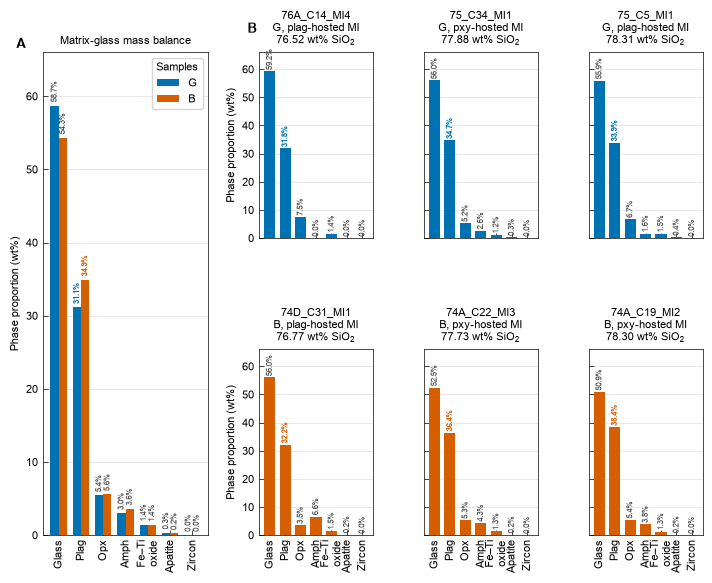

In [6]:
PHASE_LABELS = ['Glass', 'Plag', 'Opx', 'Amph', 'Fe–Ti\noxide', 'Apatite', 'Zircon']
COLORS = {'G': '#0072B2', 'B': '#D55E00'}
mi_order = mi_summary.assign(group_order=mi_summary['group'].map({'G': 0, 'B': 1})).sort_values(['group_order', 'SiO2_SEMGlass_AnhydoNorm', 'mi_id'])['mi_id'].to_list()
figure = plt.figure(figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
grid = figure.add_gridspec(2, 4, width_ratios=[1.45, 1.0, 1.0, 1.0], height_ratios=[1, 1])
x_positions = np.arange(len(PHASES))

axis_a = figure.add_subplot(grid[:, 0])
bar_width = 0.37
for offset, group in [(-bar_width / 2, 'G'), (bar_width / 2, 'B')]:
    values = matrix_fit.loc[matrix_fit['group'].eq(group)].set_index('phase').loc[PHASES, 'mass_percent']
    bars = axis_a.bar(x_positions + offset, values, width=bar_width, color=COLORS[group], label=group)
    for phase_index, bar in enumerate(bars):
        value = bar.get_height()
        highlight = phase_index == PHASES.index('plagioclase')
        axis_a.text(bar.get_x() + bar.get_width() / 2, value + 0.45, f'{value:.1f}%', ha='center', va='bottom', fontsize=SMALL_BAR_LABEL_SIZE_PT, color=COLORS[group] if highlight else '#404040', fontweight='bold' if highlight else 'normal', rotation=90)
axis_a.set_xticks(x_positions, PHASE_LABELS, rotation=90)
axis_a.set_ylim(0, 66)
axis_a.set_ylabel('Phase proportion (wt%)')
axis_a.set_title('Matrix-glass mass balance')
axis_a.legend(title='Samples', frameon=True)
axis_a.grid(axis='y', color='#D9D9D9', linewidth=0.4)
axis_a.set_axisbelow(True)
for spine in axis_a.spines.values():
    spine.set_visible(True)
axis_a.text(-0.16, 1.03, 'A', transform=axis_a.transAxes, fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', va='top')

mi_axes = []
for panel_index, mi_id in enumerate(mi_order):
    row_index, column_index = divmod(panel_index, 3)
    axis = figure.add_subplot(grid[row_index, column_index + 1])
    mi_axes.append(axis)
    values = mi_proportions.loc[mi_proportions['mi_id'].eq(mi_id)].set_index('phase').loc[PHASES, 'mass_percent']
    metadata = mi_summary.loc[mi_summary['mi_id'].eq(mi_id)].iloc[0]
    bars = axis.bar(x_positions, values, color=COLORS[metadata['group']], width=0.72)
    for phase_index, bar in enumerate(bars):
        value = bar.get_height()
        highlight = phase_index == PHASES.index('plagioclase')
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.45, f'{value:.1f}%', ha='center', va='bottom', fontsize=SMALL_BAR_LABEL_SIZE_PT, color=COLORS[metadata['group']] if highlight else '#404040', fontweight='bold' if highlight else 'normal', rotation=90)
    axis.set_ylim(0, 66)
    axis.set_xticks(x_positions, PHASE_LABELS if row_index == 1 else [], rotation=90)
    if column_index == 0:
        axis.set_ylabel('Phase proportion (wt%)')
    else:
        axis.tick_params(labelleft=False)
    host_label = 'plag-hosted' if metadata['mi_host_phase'] == 'plag' else 'pxy-hosted'
    axis.set_title(f"{mi_id}\n{metadata['group']}, {host_label} MI\n{metadata['SiO2_SEMGlass_AnhydoNorm']:.2f} wt% SiO$_2$")
    axis.grid(axis='y', color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    for spine in axis.spines.values():
        spine.set_visible(True)
mi_axes[0].text(-0.10, 1.16, 'B', transform=mi_axes[0].transAxes, fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', va='top')
figure.subplots_adjust(left=0.08, right=0.99, bottom=0.14, top=0.85, wspace=0.40, hspace=0.60)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S10_Mass_Balance.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S10_Mass_Balance.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S10_Mass_Balance.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)
print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()